# Fitness

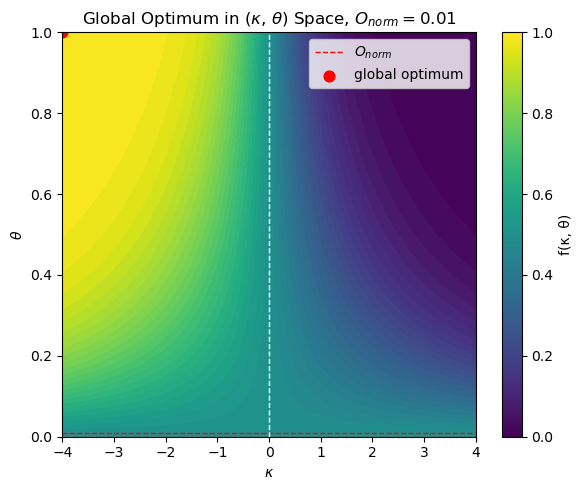

rho=0.01 -> (kappa*, theta*) = (-4.000, 1.000)


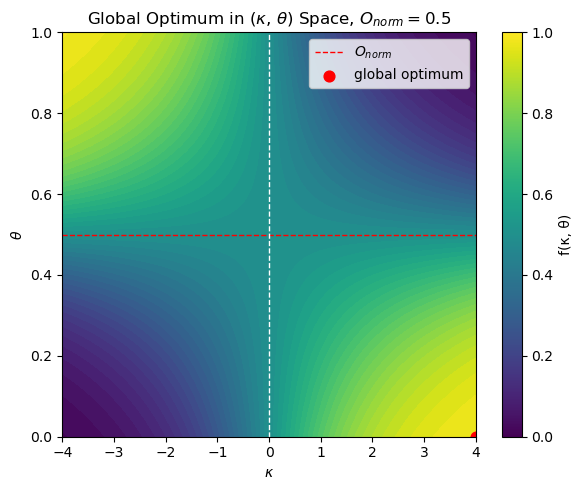

rho=0.5 -> (kappa*, theta*) = (4.000, 0.000)


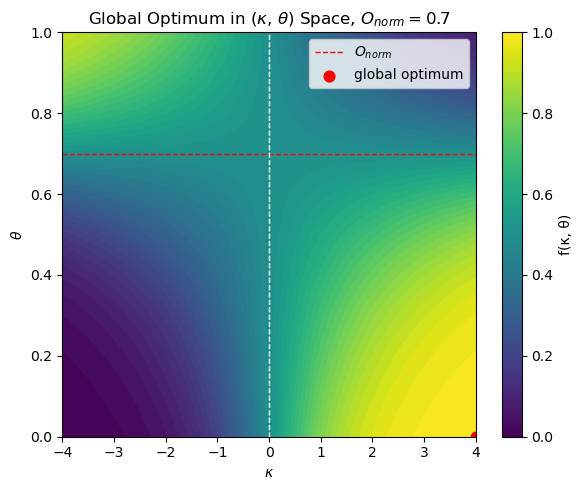

rho=0.7 -> (kappa*, theta*) = (4.000, 0.000)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# grid
kappa = np.linspace(-4, 4, 500)
theta = np.linspace(0, 1, 500)
K, T = np.meshgrid(kappa, theta)

def f(kappa, theta, rho):
    return 0.5 * (1 + np.tanh(kappa * (rho - theta)))

def find_argmax(F):
    idx = np.unravel_index(np.argmax(F), F.shape)
    return idx

def plot_for_rho(rho):
    F = f(K, T, rho)

    # argmax on grid
    i, j = find_argmax(F)
    k_star = K[i, j]
    t_star = T[i, j]

    plt.figure(figsize=(6, 5))
    plt.contourf(K, T, F, levels=60, cmap="viridis", vmin=0, vmax=1)

    # decision boundary
    plt.axhline(rho, color="red", linestyle="--", linewidth=1, label="$O_{{norm}}$")

    # kappa sign boundary
    plt.axvline(0, color="white", linestyle="--", linewidth=1)

    # true argmax
    plt.scatter(k_star, t_star, color="red", s=60, label="global optimum")

    plt.title(rf"Global Optimum in ($\kappa$, $\theta$) Space, $O_{{norm}} = {rho}$")
    plt.xlabel(r"$\kappa$")
    plt.ylabel(r"$\theta$")
    plt.xlim(-4, 4)
    plt.ylim(0, 1)

    plt.colorbar(label="f(κ, θ)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"rho={rho} -> (kappa*, theta*) = ({k_star:.3f}, {t_star:.3f})")


for rho in [0.1, 0.5, 0.7]:
    plot_for_rho(rho)

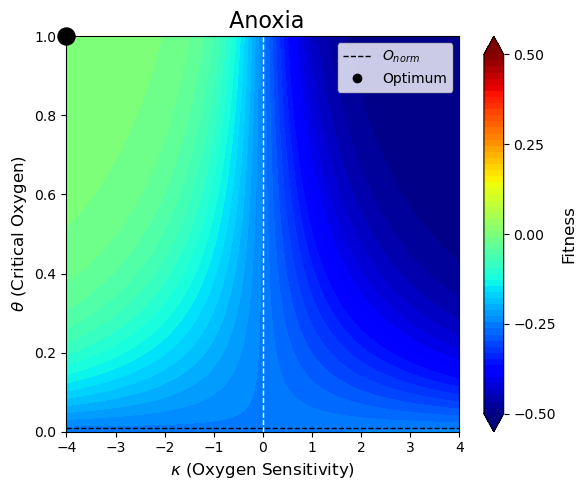

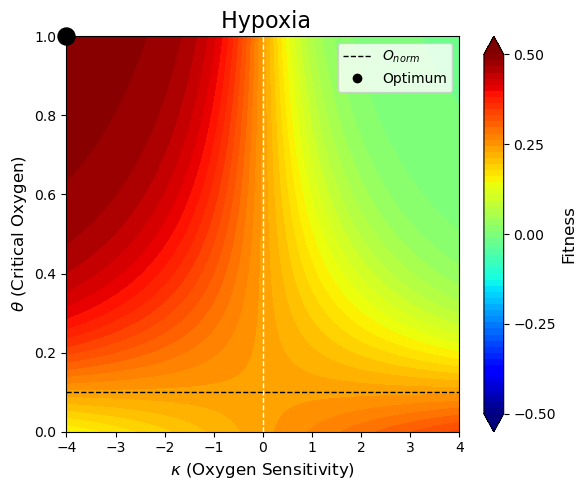

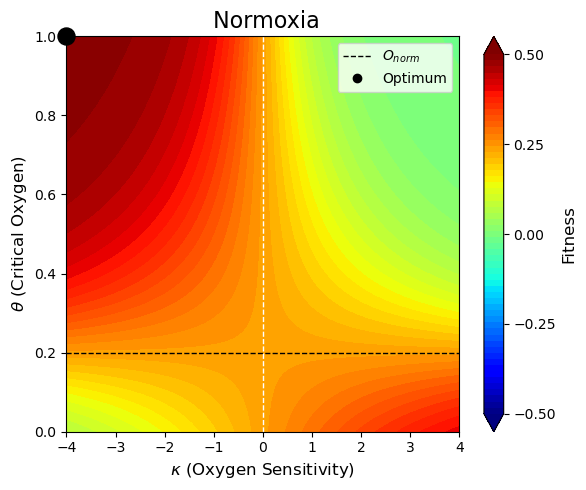

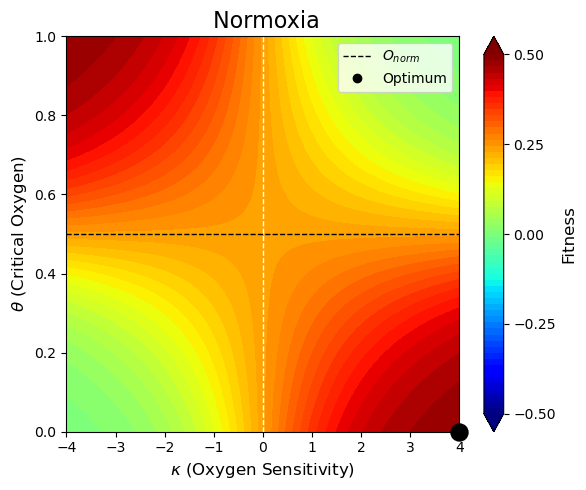

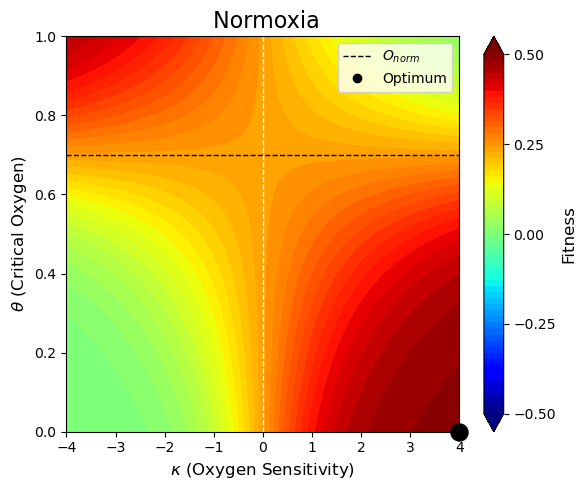

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# grid
kappa = np.linspace(-4, 4, 500)
theta = np.linspace(0, 1, 500)
K, T = np.meshgrid(kappa, theta)

alpha = 1
m = 0.5
rho_c = 7/600

def delta(rho):
    return 0.01 if rho >= rho_c else 0.5

def switch(K, T, rho):
    return 0.5 * (1 + np.tanh(K * (rho - T)))

def fitness(K, T, rho):
    return alpha * (1 - m) * switch(K, T, rho) - delta(rho)


def plot(rho):
    F = fitness(K, T, rho)

    # GLOBAL ARGMAX
    i, j = np.unravel_index(np.argmax(F), F.shape)
    k_star = K[i, j]
    t_star = T[i, j]

    plt.figure(figsize=(6, 5))

    im = plt.contourf(
    K, T, F,
    levels=np.linspace(-0.5, 0.5, 60),
    cmap="jet",
    vmin=-0.5,
    vmax=0.5,
    extend="both")



    # structure lines
    plt.axhline(rho, color="black", linestyle="--", linewidth=1, label="$O_{{norm}}$")
    plt.axvline(0, color="white", linestyle="--", linewidth=1)

    # GLOBAL OPTIMUM POINT
    plt.scatter(
        k_star,
        t_star,
        color="black",
        s=150,
        label="_nolegend_",clip_on=False
    )

    if rho < 0.0117:
        oxygen_state = "Anoxia"
    elif rho < 0.117 and rho >= 0.0117:
        oxygen_state = "Hypoxia"
    else:
        oxygen_state = "Normoxia"

    plt.title(rf" {oxygen_state}", fontsize=16)
    plt.xlabel(r"$\kappa$ (Oxygen Sensitivity)", fontsize=12)
    plt.ylabel(r"$\theta$ (Critical Oxygen)", fontsize=12)
    plt.xlim(-4, 4)
    plt.ylim(0, 1)

    cbar = plt.colorbar(im, ticks=np.linspace(-0.5, 0.5, 5))
    cbar.set_label("Fitness", fontsize=12)

    legend_dot = Line2D(
    [0], [0],
    marker='o',
    linestyle='None',
    markerfacecolor='black',
    markeredgecolor='black',
    markersize=6,
    label='Optimum')

    legend_line = Line2D(
    [0], [0],
    color='black',
    linestyle='--',
    linewidth=1,
    label=r'$O_{norm}$')

    plt.legend(handles=[legend_line, legend_dot])

    plt.tight_layout()

    plt.savefig(
    f"Fitness Plots, {rho:.3f}.png",
    dpi=300,
    bbox_inches="tight"
)


    plt.show()

    #print(f"ρ={rho:.3f} → (κ*, θ*) = ({k_star:.3f}, {t_star:.3f})")


for rho in [0.01, 0.1, 0.2, 0.5, 0.7]:
    plot(rho)

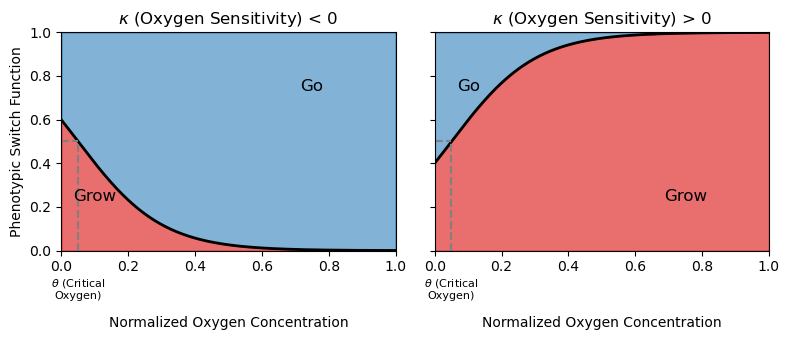

In [24]:
import numpy as np
import matplotlib.pyplot as plt

rho = np.linspace(0, 1, 500)
theta = 0.05
kappas = [-4, 4]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
for ax, kappa in zip(axes, kappas):
    switch = 0.5 * (1 + np.tanh(kappa * (rho - theta)))

    ax.fill_between(rho, switch, 1, color="#0667ac", alpha=0.5)
    ax.fill_between(rho, 0, switch, color="#e03030", alpha=0.7)

    ax.plot(rho, switch, color="black", lw=2)

    # L-shaped threshold marker
    ax.plot([theta, theta], [0, 0.5], color="gray", linestyle="--", lw=1.5)
    ax.plot([0, theta], [0.5, 0.5], color="gray", linestyle="--", lw=1.5)

# theta label
    ax.text(theta, -0.12, r'$\theta$ (Critical' + '\n' + 'Oxygen)',
        ha='center', va='top', fontsize=8)

    if kappa < 0:
        ax.text(0.1, 0.25, "Grow", ha="center", va="center", fontsize=12)
        ax.text(0.75, 0.75, "Go", ha="center", va="center", fontsize=12)
    if kappa > 0:
        ax.text(0.1, 0.75, "Go", ha="center", va="center", fontsize=12)
        ax.text(0.75, 0.25, "Grow", ha="center", va="center", fontsize=12)

    if kappa > 0:
        ax.set_title(r'$\kappa$ (Oxygen Sensitivity) > 0')
    else:
        ax.set_title(r'$\kappa$ (Oxygen Sensitivity) < 0')

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(r'Normalized Oxygen Concentration', labelpad=30)
    ax.grid(False)
    
axes[0].set_ylabel('Phenotypic Switch Function')

plt.savefig("switch_function_3.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

# Treatment

/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py:38: RuntimeWarning: invalid value encountered in scalar divide
  pmigr = total_migrating / total_cells
/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py:39: RuntimeWarning: invalid value encountered in scalar divide
  pprolif = total_proliferating / total_cells
/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py:38: RuntimeWarning: invalid value encountered in scalar divide
  pmigr = total_migrating / total_cells
/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py:39: RuntimeWarning: invalid value encountered in scalar divide
  pprolif = total_proliferating / total_cells
/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py:38: RuntimeWarning: invalid value encountered in scalar divide
  pmigr = total_migrating / total_cells
/var/folders/yc/xfnnny1j5zldw2s7dtxc1tnm0000gn/T/ipykernel_15801/1036462059.py

Spearman correlation matrix:
                          oxygen     kappa  migrating  density      node  \
oxygen                  1.000000 -0.436275   0.170783      NaN  0.365196   
kappa                  -0.436275  1.000000   0.365963      NaN -0.026961   
migrating               0.170783  0.365963   1.000000      NaN  0.000000   
density                      NaN       NaN        NaN      NaN       NaN   
node                    0.365196 -0.026961   0.000000      NaN  1.000000   
proliferating          -0.170783 -0.365963  -1.000000      NaN  0.000000   
theta                  -0.291667  0.272059   0.414758      NaN  0.000000   
invasion_distance       0.365196 -0.026961   0.000000      NaN  1.000000   
recurrence_time         0.083875  0.062183   0.143950      NaN  0.109906   
entropy                 0.238272 -0.141392  -0.026064      NaN  0.230417   
migration_fraction      0.170783  0.365963   1.000000      NaN  0.000000   
proliferation_fraction -0.170783 -0.365963  -1.000000      

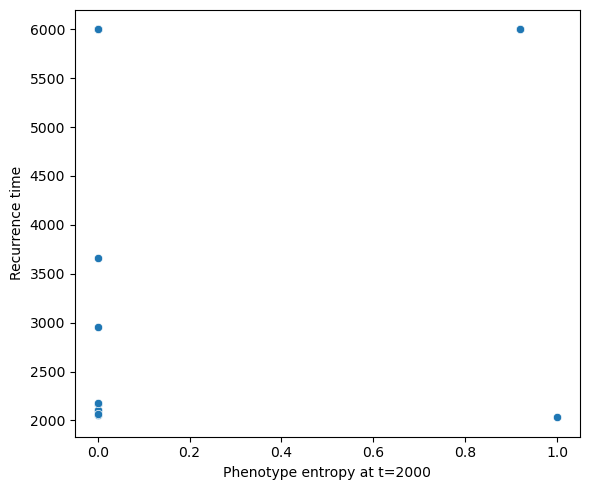

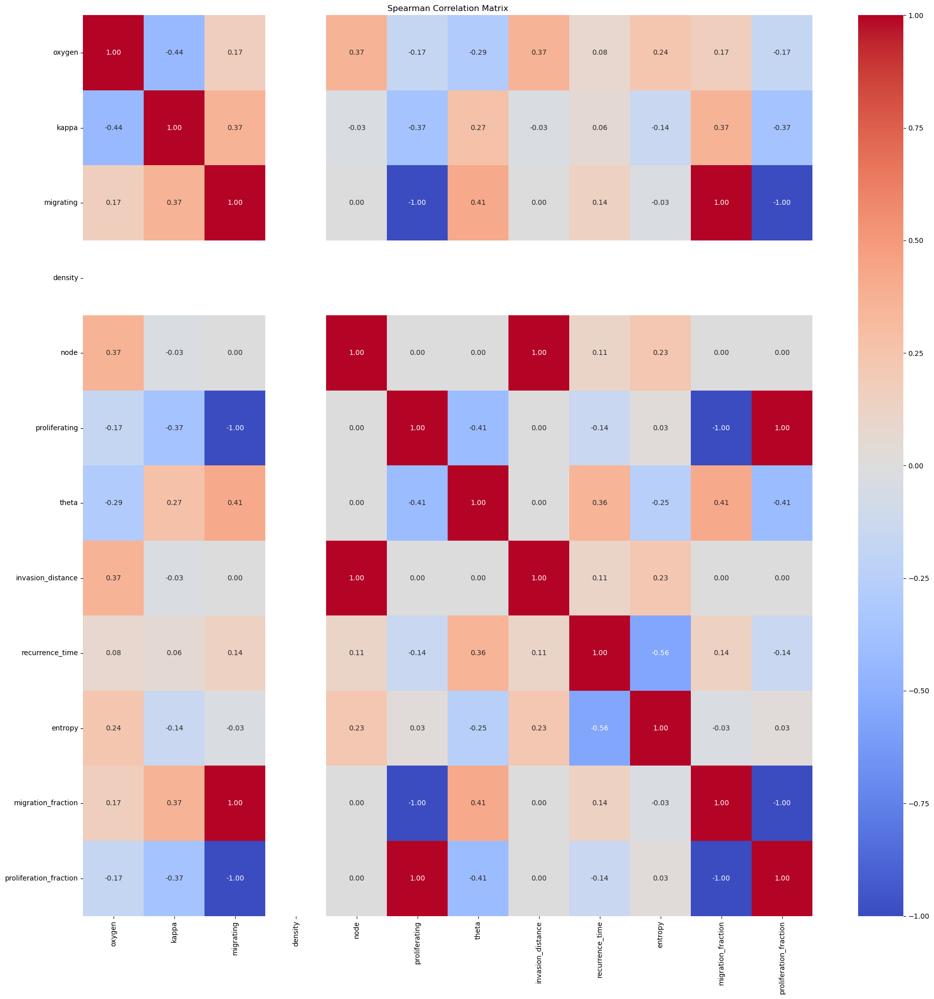

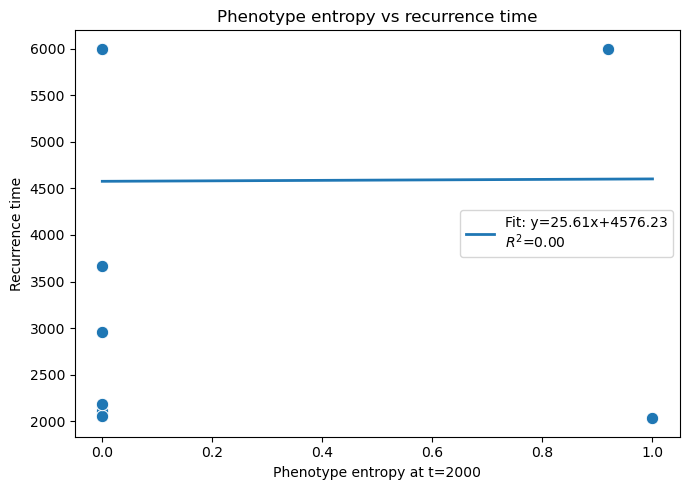

Linear regression:
slope = 25.61315706116577
intercept = 4576.232431829841
R² = 2.0537124377282054e-05
p-value = 0.9836271961717573


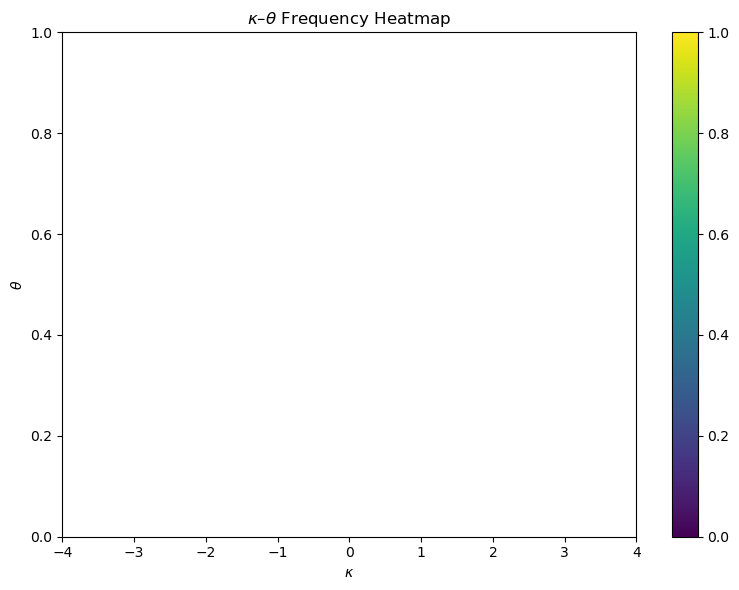

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = "/Users/lexiwhiteside/Downloads/biolgca-master/25062026_clog_treatment/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)
pd.reset_option("display.float_format")
dfs = []
summary_rows = []
skip_sheets = {"run_17"}
for sheet in xls.sheet_names:
    if sheet in skip_sheets:
        continue  # skip summary sheet
    df = pd.read_excel(xls, sheet_name=sheet)


    recurrence_time = df["time"].max()
    

    # filter timestep
    df2k = df[df["time"] == 2000 ]
    
    # keep relevant columns only
    df2k = df2k[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

    df2k["invasion_distance"] = np.abs(df2k["node"] - 1000)

    df2k["recurrence_time"] = recurrence_time

    df2k_active = df2k[df2k["density"] > 0].copy()
    total_migrating = df2k_active["migrating"].sum()
    total_proliferating = df2k_active["proliferating"].sum()
    total_cells = total_migrating + total_proliferating
    pmigr = total_migrating / total_cells
    pprolif = total_proliferating / total_cells
    entropy = 0
    if pmigr > 0:
        entropy -= pmigr * np.log2(pmigr)
    if pprolif > 0:
        entropy -= pprolif * np.log2(pprolif)
    df2k["entropy"] = entropy
    
    summary_rows.append({
    "run": sheet,
    "entropy": entropy,
    "recurrence_time": recurrence_time
})
    
    dfs.append(df2k)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])



#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)

# entropy vs recurrence time correlation
summary = pd.DataFrame(summary_rows)

print("\nEntropy per run:")
print(summary)

rho, p = spearmanr(
    summary["entropy"],
    summary["recurrence_time"]
)

print("\nSpearman entropy vs recurrence time")
print("rho =", rho)
print("p-value =", p)


plt.figure(figsize=(6,5))
sns.scatterplot(
    data=summary,
    x="entropy",
    y="recurrence_time"
)

plt.xlabel("Phenotype entropy at t=2000")
plt.ylabel("Recurrence time")
plt.tight_layout()
plt.show()

plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

from scipy.stats import linregress

# linear regression
slope, intercept, r_value, p_value, std_err = linregress(
    summary["entropy"],
    summary["recurrence_time"]
)

# predicted values for line
x = np.linspace(
    summary["entropy"].min(),
    summary["entropy"].max(),
    100
)

y = slope * x + intercept


# plot
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=summary,
    x="entropy",
    y="recurrence_time",
    s=80
)

plt.plot(
    x,
    y,
    linewidth=2,
    label=f"Fit: y={slope:.2f}x+{intercept:.2f}\n$R^2$={r_value**2:.2f}"
)

plt.xlabel("Phenotype entropy at t=2000")
plt.ylabel("Recurrence time")
plt.title("Phenotype entropy vs recurrence time")

plt.legend()
plt.tight_layout()
plt.show()


print("Linear regression:")
print("slope =", slope)
print("intercept =", intercept)
print("R² =", r_value**2)
print("p-value =", p_value)


# heatmap 
plt.figure(figsize=(8,6))


sns.histplot(
    data=pooled_active,
    x="kappa",
    y="theta",
    bins=80,
    cmap="viridis",
    cbar=True,  
    thresh=55 )

plt.xlabel(r"$\kappa$")
plt.ylabel(r"$\theta$")
plt.xlim(-4, 4)
plt.ylim(0, 1)
plt.title(r"$\kappa$–$\theta$ Frequency Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = "/Users/lexiwhiteside/Downloads/biolgca-master/23062026_noclog_treatment/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)
pd.reset_option("display.float_format")
dfs = []
summary_rows = []
#skip_sheets = {"run_17"}
for sheet in xls.sheet_names:
    #if sheet in skip_sheets:
        #continue  # skip summary sheet
    df = pd.read_excel(xls, sheet_name=sheet)


    recurrence_time = df["time"].max()
    

    # filter timestep
    df2k = df[df["time"] == 2000 ]
    
    # keep relevant columns only
    df2k = df2k[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

    df2k["invasion_distance"] = np.abs(df2k["node"] - 1000)

    df2k["recurrence_time"] = recurrence_time
    
    dfs.append(df2k)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])

#entropy
pm = pooled_active["migration_fraction"]
pp = pooled_active["proliferation_fraction"]
pooled_active["phenotype_entropy"] = (-np.where(pm > 0, pm * np.log2(pm), 0)-np.where(pp > 0, pp * np.log2(pp), 0))

#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)


plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

# New

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000  0.006383  -0.015963 -0.018188  0.016637   
kappa                   0.006383  1.000000  -0.689087  0.003114  0.042863   
migrating              -0.015963 -0.689087   1.000000  0.337437 -0.020937   
density                -0.018188  0.003114   0.337437  1.000000 -0.005127   
node                    0.016637  0.042863  -0.020937 -0.005127  1.000000   
proliferating          -0.008255  0.632821  -0.591441  0.513157  0.011766   
theta                   0.032061 -0.570420   0.651928  0.002176  0.038443   
invasion_distance      -0.003590 -0.515429   0.589007  0.000817 -0.017587   
migration_fraction     -0.005831 -0.742611   0.946944  0.065217 -0.019142   
proliferation_fraction  0.005831  0.742611  -0.946944 -0.065217  0.019142   

                        proliferating     theta  invasion_distance  \
oxygen                      -0.008255  0.032061      

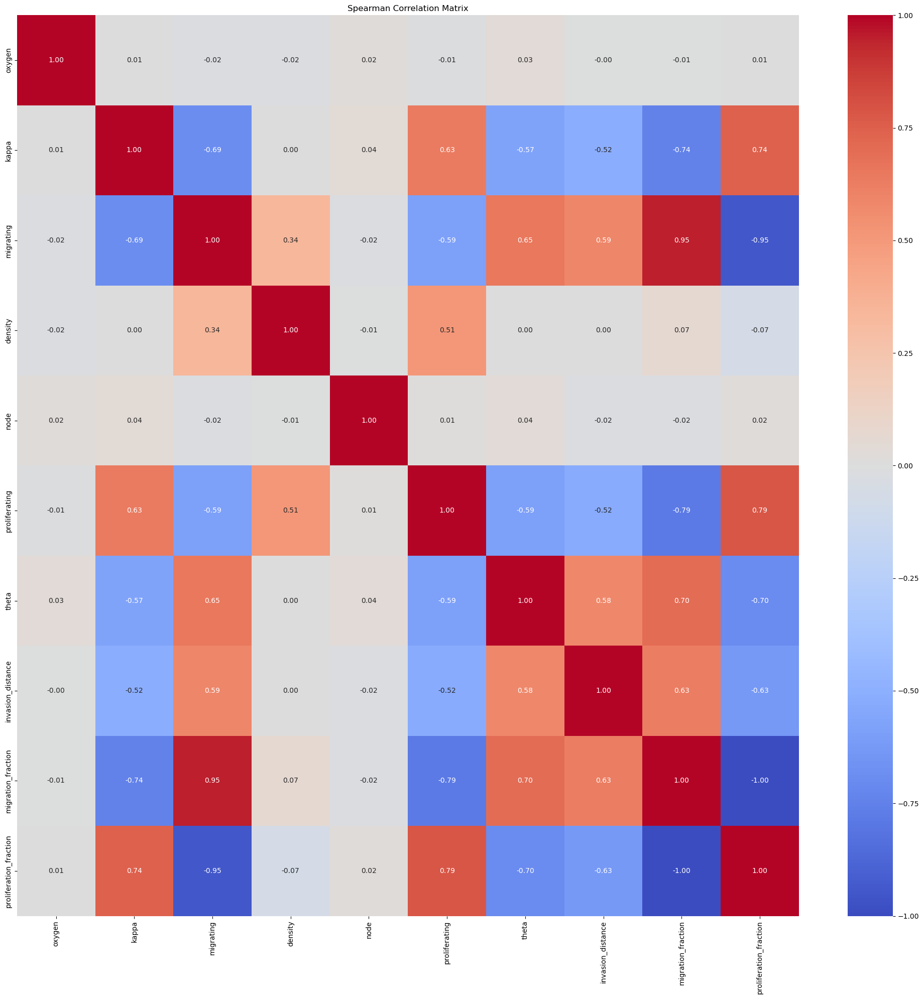

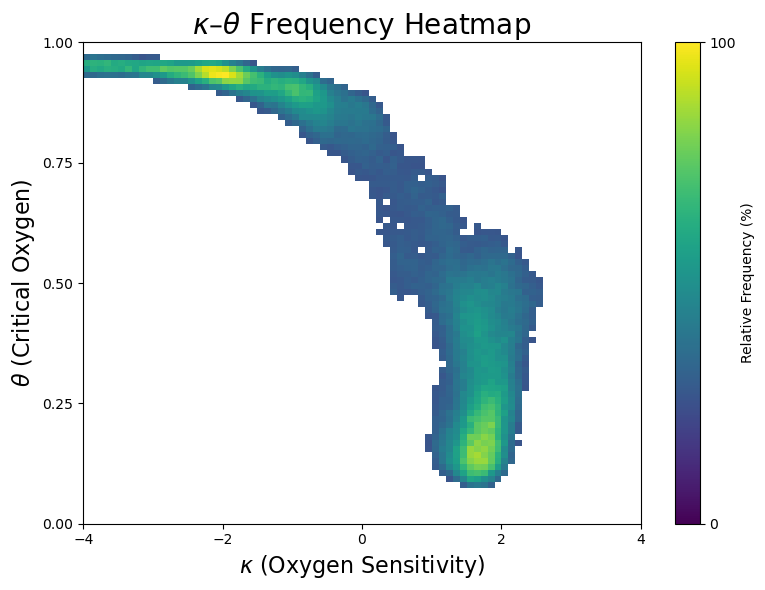

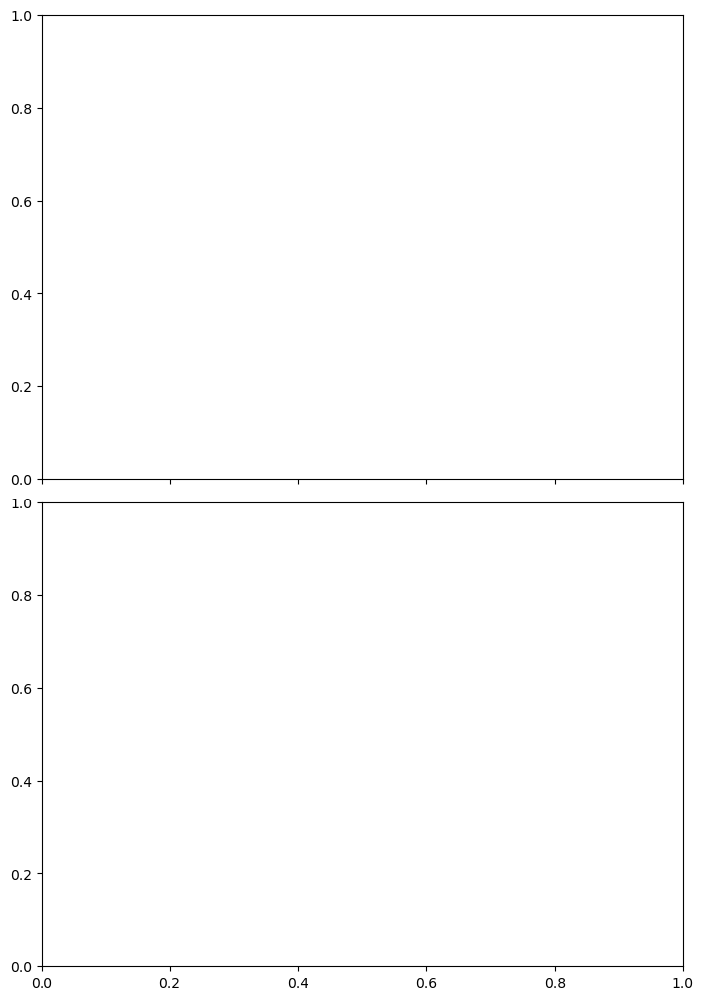

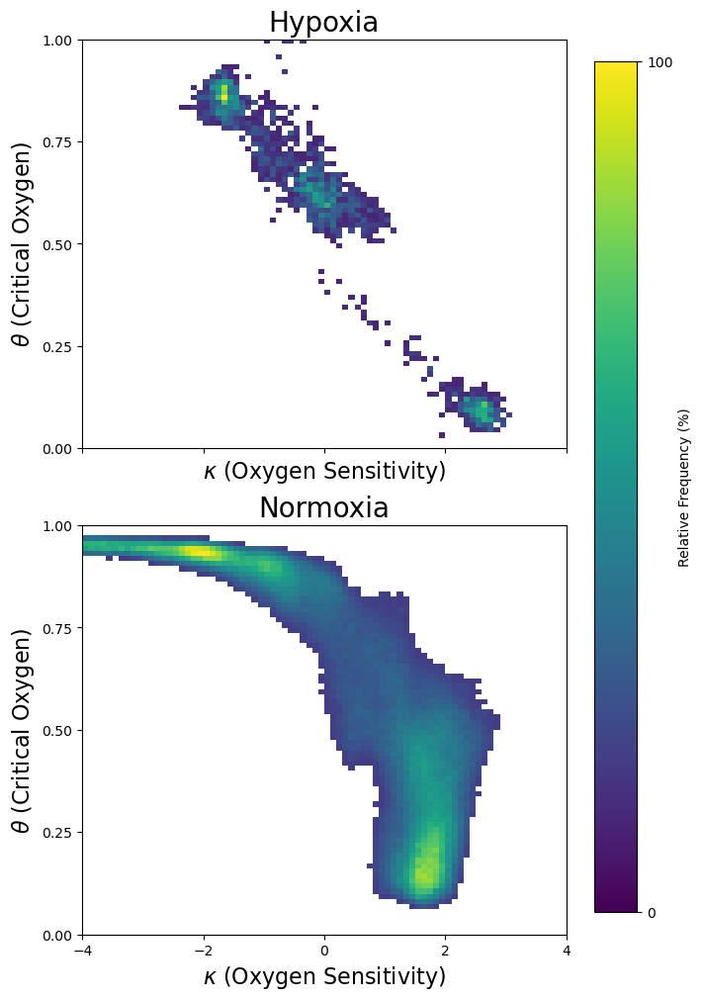

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = ["/Users/lexiwhiteside/Downloads/biolgca-master/08212026_no_clog_runs0to25/lgca_1d_no_clogging.xlsx",
        "/Users/lexiwhiteside/Downloads/biolgca-master/08212026_no_clog_runs25to50/lgca_1d_no_clogging.xlsx"]
pd.reset_option("display.float_format")
dfs = []
summary_rows = []
for file in file:
    xls = pd.ExcelFile(file)

    for sheet in xls.sheet_names:
        df = pd.read_excel(xls, sheet_name=sheet)
        
        # filter timestep
        df = df[df["time"] > 1960 ]
        
        # keep relevant columns only
        df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

        df["invasion_distance"] = np.abs(df["node"] - 1000)

        # moving front
        #threshold = 1e-6
        #occupied = df[df["density"] > threshold]
        #if len(occupied) > 0:
            #width = occupied["node"].max() - occupied["node"].min() + 1
        #else:
            #width = 0
        
        dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)


plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()


# heatmap 
# heatmap
counts, xedges, yedges = np.histogram2d(
    pooled_active["kappa"],
    pooled_active["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

# Normalize so the highest density bin = 100%
percent = 100 * counts / counts.max()
threshold = np.percentile(percent[percent > 0], 75)  # cutoff at 40th percentile
percent[percent < threshold] = np.nan

plt.figure(figsize=(8,6))

im=plt.imshow(
    percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],   # x_min, x_max, y_min, y_max
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100
)

cbar = plt.colorbar(im)
cbar.set_label("Relative Frequency (%)")
cbar.set_ticks([0, 100])
cbar.set_ticklabels(["0", "100"])



# Correct axis labels
plt.xticks(
    np.linspace(-4, 4, 5)
)

plt.yticks(
    np.linspace(0, 1, 5)
)

plt.xlabel(r"$\kappa$ (Oxygen Sensitivity)", fontsize=16)
plt.ylabel(r"$\theta$ (Critical Oxygen)", fontsize=16)
plt.title(r"$\kappa$–$\theta$ Frequency Heatmap", fontsize=20)

plt.tight_layout()
plt.savefig("kappa_theta_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
# divide
fig, axes = plt.subplots(
    2, 1,
    figsize=(7, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
low_oxygen = pooled_active[pooled_active["oxygen"] < 2.303e-7]
high_oxygen = pooled_active[pooled_active["oxygen"] >= 2.303e-7]

# Compute histograms
low_counts, _, _ = np.histogram2d(
    low_oxygen["kappa"],
    low_oxygen["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

high_counts, _, _ = np.histogram2d(
    high_oxygen["kappa"],
    high_oxygen["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

# Normalize to 0-100%
low_percent = 100 * low_counts / low_counts.max()
high_percent = 100 * high_counts / high_counts.max()

threshold = np.percentile(low_percent[low_percent > 0], 75)  # cutoff at 40th percentile
low_percent[low_percent < threshold] = np.nan

threshold = np.percentile(high_percent[high_percent > 0], 75)  # cutoff at 40th percentile
high_percent[high_percent < threshold] = np.nan


fig, axes = plt.subplots(
    2, 1,
    figsize=(7, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
im1 = axes[0].imshow(
    low_percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
)

im2 = axes[1].imshow(
    high_percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
 
)


cbar = fig.colorbar(
    im2,
    ax=axes,
    location="right",
    shrink=0.95
)

cbar.set_label("Relative Frequency (%)")
cbar.set_ticks([0, 100])
cbar.set_ticklabels(["0", "100"])


for ax, title in zip(axes, ["Hypoxia", "Normoxia"]):
    ax.set_title(title, fontsize=20)
    ax.set_xlabel(r"$\kappa$ (Oxygen Sensitivity)", fontsize=16)
    ax.set_ylabel(r"$\theta$ (Critical Oxygen)", fontsize=16)

    # Convert heatmap indices back to parameter values
    ax.set_xticks(np.linspace(-4, 4, 5))
    ax.set_yticks(np.linspace(0, 1, 5))

#plt.tight_layout()
plt.savefig("kappa_theta_heatmap_oxlevels.png", dpi=300, bbox_inches="tight")
plt.show()

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000  0.043682   0.119596  0.122809 -0.012655   
kappa                   0.043682  1.000000   0.377127 -0.122056  0.036400   
migrating               0.119596  0.377127   1.000000  0.620684  0.033766   
density                 0.122809 -0.122056   0.620684  1.000000  0.004803   
node                   -0.012655  0.036400   0.033766  0.004803  1.000000   
proliferating           0.098943 -0.497894  -0.039473  0.698749 -0.025053   
theta                   0.005850  0.078546  -0.072537 -0.054316  0.188547   
invasion_distance       0.452820 -0.002383   0.036020  0.035840  0.024176   
migration_fraction      0.008230  0.569457   0.554192 -0.147857  0.035785   
proliferation_fraction -0.008230 -0.569457  -0.554192  0.147857 -0.035785   

                        proliferating     theta  invasion_distance  \
oxygen                       0.098943  0.005850      

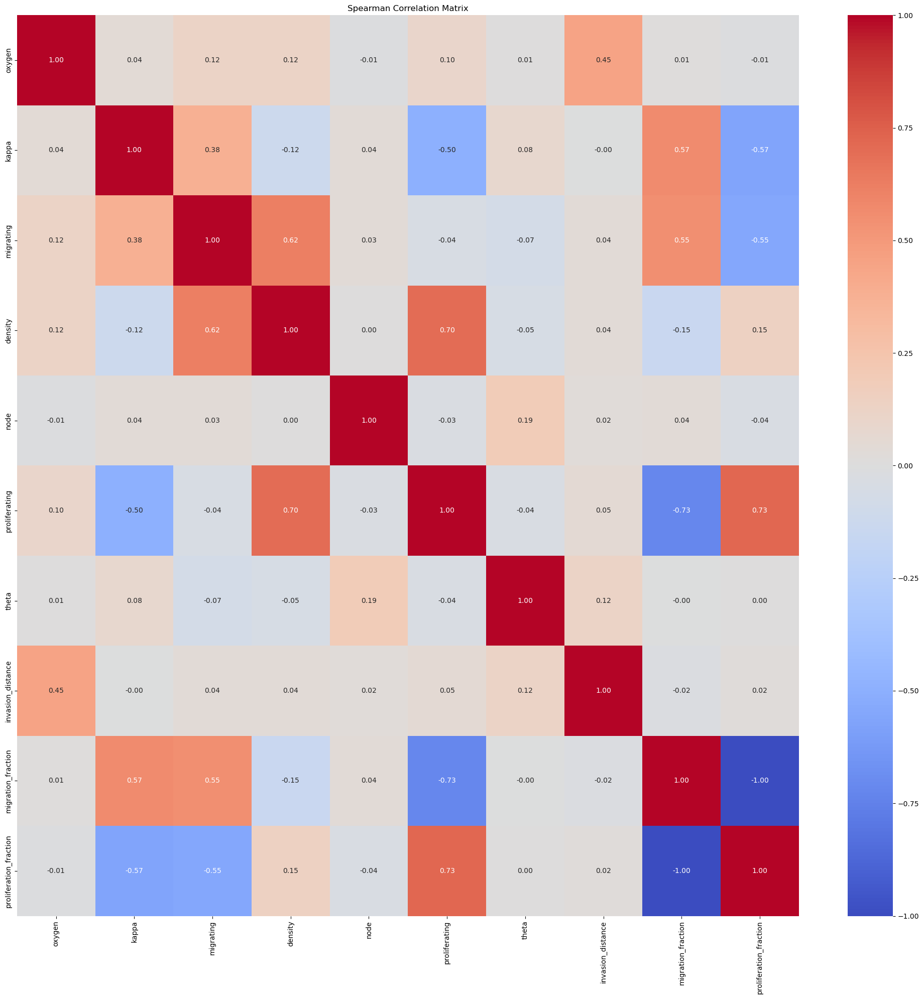

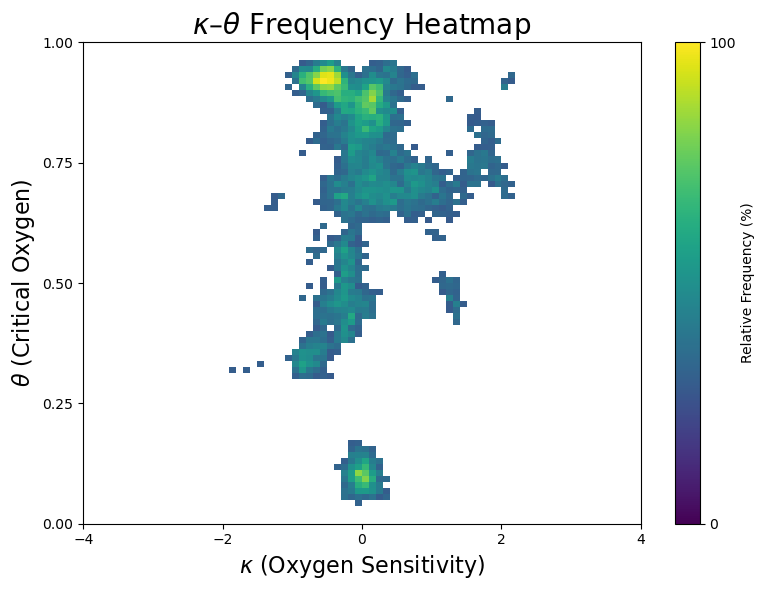

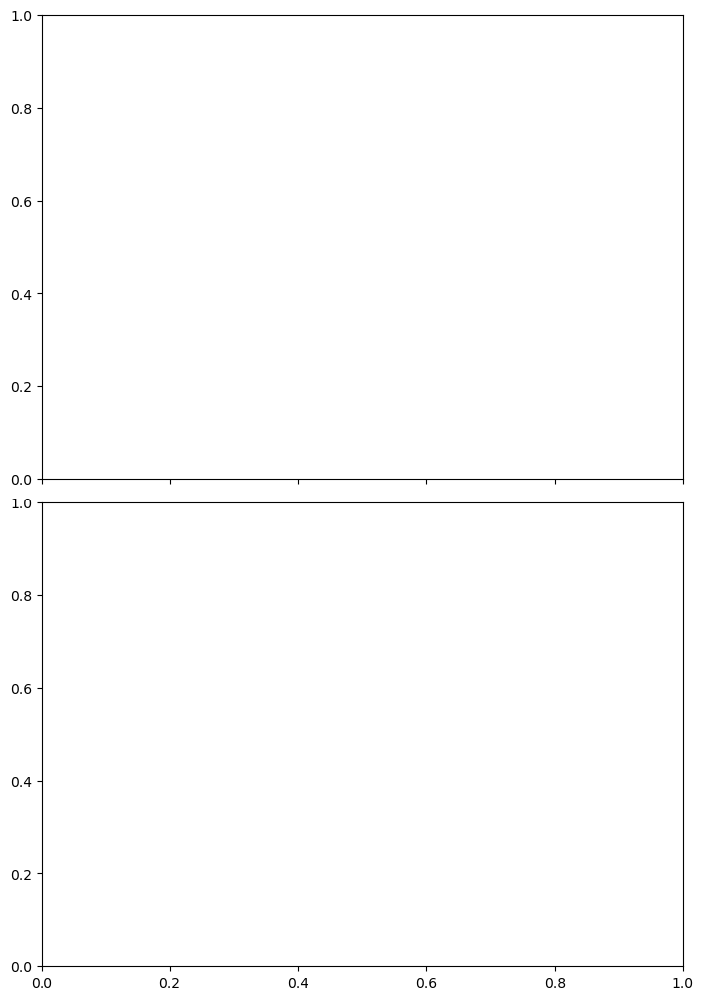

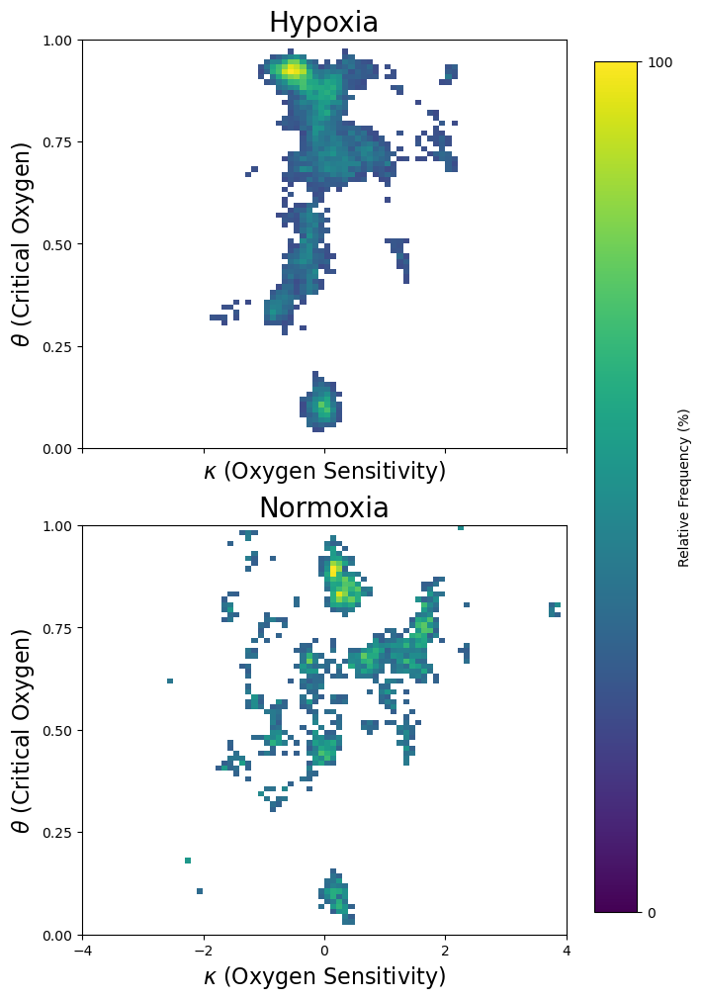

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = ["/Users/lexiwhiteside/Downloads/biolgca-master/08212026_clog_runs0to25/lgca_1d_no_clogging.xlsx",
        "/Users/lexiwhiteside/Downloads/biolgca-master/08212026_clog_runs26to50/lgca_1d_no_clogging.xlsx"]
pd.reset_option("display.float_format")
dfs = []
summary_rows = []
for file in file:
    xls = pd.ExcelFile(file)
    for sheet in xls.sheet_names:
        df = pd.read_excel(xls, sheet_name=sheet)
        
        # filter timestep
        df = df[df["time"] > 1960 ]
        
        # keep relevant columns only
        df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

        df["invasion_distance"] = np.abs(df["node"] - 1000)

        # moving front
        #threshold = 1e-6
        #occupied = df[df["density"] > threshold]
        #if len(occupied) > 0:
            #width = occupied["node"].max() - occupied["node"].min() + 1
        #else:
            #width = 0
        
        dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)


plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()


# heatmap 
# heatmap
counts, xedges, yedges = np.histogram2d(
    pooled_active["kappa"],
    pooled_active["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

# Normalize so the highest density bin = 100%
percent = 100 * counts / counts.max()
threshold = np.percentile(percent[percent > 0], 85)  # cutoff at 40th percentile
percent[percent < threshold] = np.nan

plt.figure(figsize=(8,6))

im=plt.imshow(
    percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],   # x_min, x_max, y_min, y_max
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100
)

cbar = plt.colorbar(im)
cbar.set_label("Relative Frequency (%)")
cbar.set_ticks([0, 100])
cbar.set_ticklabels(["0", "100"])



# Correct axis labels
plt.xticks(
    np.linspace(-4, 4, 5)
)

plt.yticks(
    np.linspace(0, 1, 5)
)

plt.xlabel(r"$\kappa$ (Oxygen Sensitivity)", fontsize=16)
plt.ylabel(r"$\theta$ (Critical Oxygen)", fontsize=16)
plt.title(r"$\kappa$–$\theta$ Frequency Heatmap", fontsize=20)

plt.tight_layout()
plt.savefig("kappa_theta_heatmap_clog.png", dpi=300, bbox_inches="tight")
plt.show()
# divide
fig, axes = plt.subplots(
    2, 1,
    figsize=(7, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
low_oxygen = pooled_active[pooled_active["oxygen"] < 2.303e-7]
high_oxygen = pooled_active[pooled_active["oxygen"] >= 2.303e-7]

# Compute histograms
low_counts, _, _ = np.histogram2d(
    low_oxygen["kappa"],
    low_oxygen["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

high_counts, _, _ = np.histogram2d(
    high_oxygen["kappa"],
    high_oxygen["theta"],
    bins=80,
    range=[[-4, 4], [0, 1]]
)

# Normalize to 0-100%
low_percent = 100 * low_counts / low_counts.max()
high_percent = 100 * high_counts / high_counts.max()

threshold = np.percentile(low_percent[low_percent > 0], 85)  # cutoff at 40th percentile
low_percent[low_percent < threshold] = np.nan

threshold = np.percentile(high_percent[high_percent > 0], 85)  # cutoff at 40th percentile
high_percent[high_percent < threshold] = np.nan


fig, axes = plt.subplots(
    2, 1,
    figsize=(7, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
im1 = axes[0].imshow(
    low_percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
)

im2 = axes[1].imshow(
    high_percent.T,
    origin="lower",
    extent=[-4, 4, 0, 1],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100,
 
)


cbar = fig.colorbar(
    im2,
    ax=axes,
    location="right",
    shrink=0.95
)

cbar.set_label("Relative Frequency (%)")
cbar.set_ticks([0, 100])
cbar.set_ticklabels(["0", "100"])


for ax, title in zip(axes, ["Hypoxia", "Normoxia"]):
    ax.set_title(title, fontsize=20)
    ax.set_xlabel(r"$\kappa$ (Oxygen Sensitivity)", fontsize=16)
    ax.set_ylabel(r"$\theta$ (Critical Oxygen)", fontsize=16)

    # Convert heatmap indices back to parameter values
    ax.set_xticks(np.linspace(-4, 4, 5))
    ax.set_yticks(np.linspace(0, 1, 5))

#plt.tight_layout()
plt.savefig("kappa_theta_heatmap_oxlevels_clog.png", dpi=300, bbox_inches="tight")
plt.show()

# Strict Clogging

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import numpy as np

file = "/Users/lexiwhiteside/Downloads/biolgca-master/06052026_strict_clogging_100runs/lgca_1d_no_clogging.xlsx"
pd.reset_option("display.float_format")

xls = pd.ExcelFile(file)

dfs = []
summary_rows = []

for sheet in xls.sheet_names:

    df = pd.read_excel(xls, sheet_name=sheet)

    # filter timestep
    df = df[df["time"] > 1960]

    # base columns always required
    cols = [
        "oxygen",
        "kappa",
        "migrating",
        "density",
        "node",
        "proliferating"
    ]

    # only add theta if it exists
    if "theta" in df.columns:
        cols.append("theta")

    # keep relevant columns only
    df = df[cols].dropna()

    df["invasion_distance"] = np.abs(df["node"] - 1000)

    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)

pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


# force numeric just in case
pooled_active = pooled_active.apply(pd.to_numeric, errors="coerce")

# Spearman correlation
corr, pvals = spearmanr(pooled_active, nan_policy="omit")

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000  0.020781   0.295621  0.273752 -0.009294   
kappa                   0.020781  1.000000   0.320842 -0.162274 -0.117748   
migrating               0.295621  0.320842   1.000000  0.414286 -0.043536   
density                 0.273752 -0.162274   0.414286  1.000000  0.007388   
node                   -0.009294 -0.117748  -0.043536  0.007388  1.000000   
proliferating           0.117388 -0.353699  -0.157537  0.804439  0.029267   
invasion_distance       0.806657 -0.006239   0.227525  0.250956  0.041809   
theta                   0.443041 -0.390528   0.036323  0.199645  0.120079   
migration_fraction      0.137360  0.392147   0.777897 -0.131754 -0.038280   
proliferation_fraction -0.137360 -0.392147  -0.777897  0.131754  0.038280   

                        proliferating  invasion_distance     theta  \
oxygen                       0.117388           0.806

                            mean    median  variance   std_dev       mode
oxygen                 7.856e-08 6.461e-08 3.576e-15 5.980e-08  1.974e-07
kappa                  1.352e+00 1.179e+00 8.828e+00 2.971e+00 -3.049e+00
migration_fraction     3.434e-01 3.333e-01 5.747e-02 2.397e-01  0.000e+00
density                8.673e+00 9.000e+00 1.151e+01 3.393e+00  9.000e+00
proliferation_fraction 6.566e-01 6.667e-01 5.747e-02 2.397e-01  1.000e+00
invasion_distance      5.552e+02 5.550e+02 9.961e+02 3.156e+01  5.510e+02
theta                  4.364e-01 4.262e-01 7.821e-02 2.797e-01  0.000e+00


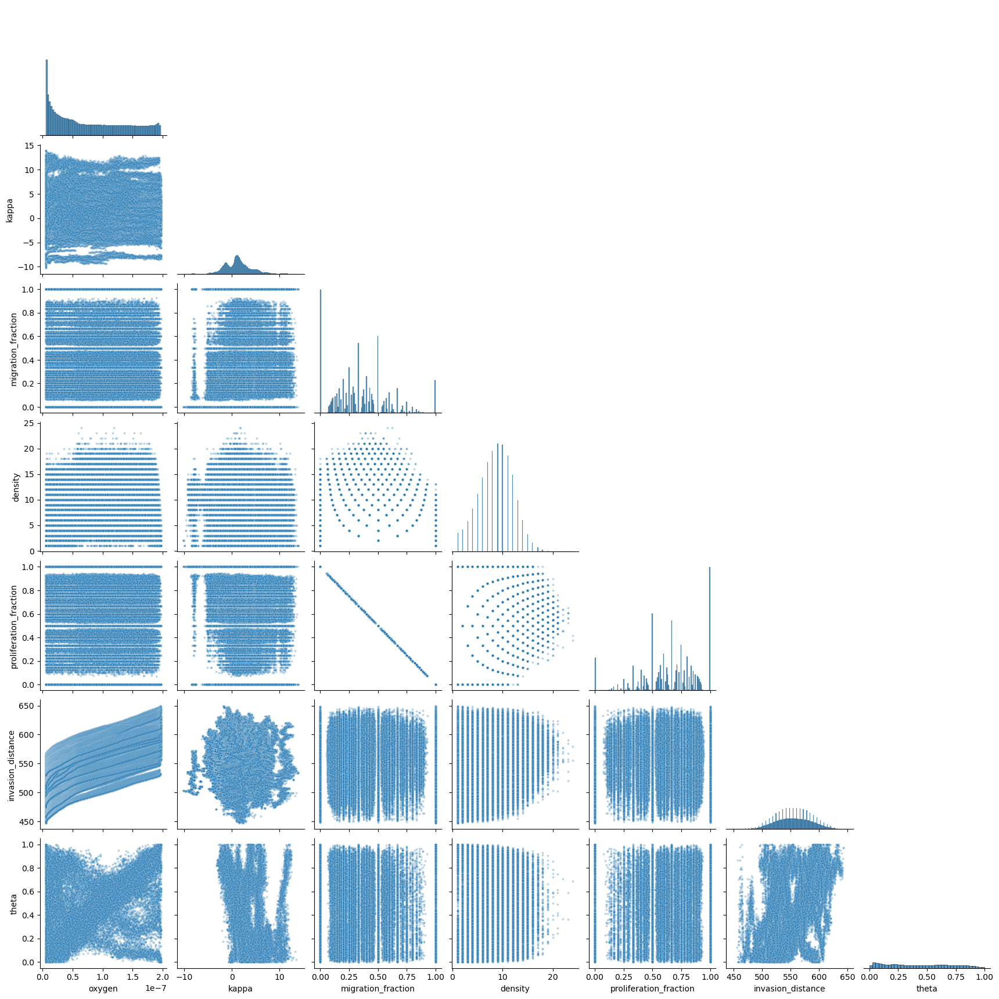

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    "oxygen",
    "kappa",
    "migration_fraction",
    "density",
    "proliferation_fraction",
    "invasion_distance",
    "theta"]

data = pooled_active[cols]

# summary stats
summary = pd.DataFrame({
    "mean": data.mean(),
    "median": data.median(),
    "variance": data.var(),
    "std_dev": data.std()})

summary["mode"] = data.mode().iloc[0]
pd.set_option("display.float_format", "{:.3e}".format)
print(summary)


# plot matrix of everything against each other
sns.pairplot(pooled_active[cols], corner=True, plot_kws={"s": 8, "alpha": 0.3})
plt.show()

# No Clogging

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
file = "/Users/lexiwhiteside/Downloads/biolgca-master/06052026_no_clogging_100runs/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)
pd.reset_option("display.float_format")
dfs = []
summary_rows = []

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    
    # filter timestep
    df = df[df["time"] > 1960 ]
    
    # keep relevant columns only
    df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

    df["invasion_distance"] = np.abs(df["node"] - 1000)

    # moving front
    #threshold = 1e-6
    #occupied = df[df["density"] > threshold]
    #if len(occupied) > 0:
        #width = occupied["node"].max() - occupied["node"].min() + 1
    #else:
        #width = 0
    
    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000  0.083369  -0.111206  0.361160 -0.000699   
kappa                   0.083369  1.000000  -0.061386  0.077388 -0.008654   
migrating              -0.111206 -0.061386   1.000000  0.075436 -0.006707   
density                 0.361160  0.077388   0.075436  1.000000  0.001671   
node                   -0.000699 -0.008654  -0.006707  0.001671  1.000000   
proliferating           0.382871  0.130839  -0.378307  0.854246  0.003223   
theta                   0.073454 -0.673980   0.010457 -0.002246  0.051510   
invasion_distance       0.090799 -0.246488   0.349572 -0.078861  0.016603   
migration_fraction     -0.174654 -0.055067   0.968274 -0.100887 -0.007433   
proliferation_fraction  0.174654  0.055067  -0.968274  0.100887  0.007433   

                        proliferating     theta  invasion_distance  \
oxygen                       0.382871  0.073454      

                            mean    median  variance   std_dev       mode
oxygen                 1.106e-07 1.210e-07 4.080e-15 6.388e-08  1.974e-07
kappa                  2.198e+00 2.795e+00 1.014e+01 3.184e+00 -2.135e+00
migration_fraction     1.232e-01 7.692e-02 3.077e-02 1.754e-01  0.000e+00
density                1.059e+01 1.100e+01 7.729e+00 2.780e+00         12
proliferation_fraction 8.768e-01 9.231e-01 3.077e-02 1.754e-01  1.000e+00
invasion_distance      2.994e+02 2.990e+02 2.982e+04 1.727e+02        520
theta                  3.511e-01 2.452e-01 8.380e-02 2.895e-01  0.000e+00


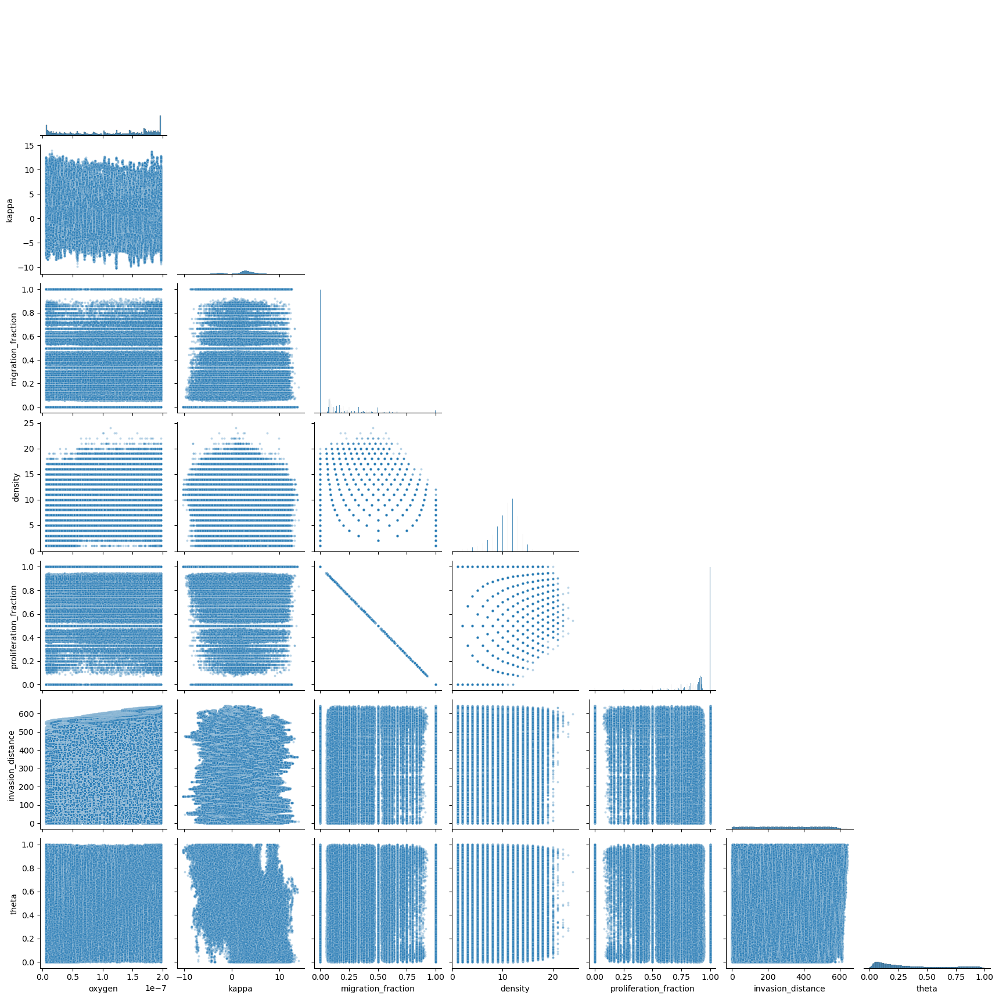

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    "oxygen",
    "kappa",
    "migration_fraction",
    "density",
    "proliferation_fraction",
    "invasion_distance",
    "theta"]

data = pooled_active[cols]

# summary stats
summary = pd.DataFrame({
    "mean": data.mean(),
    "median": data.median(),
    "variance": data.var(),
    "std_dev": data.std()})

summary["mode"] = data.mode().iloc[0]
pd.set_option("display.float_format", "{:.3e}".format)
print(summary)


# plot matrix of everything against each other
sns.pairplot(pooled_active[cols], corner=True, plot_kws={"s": 8, "alpha": 0.3})
plt.show()

# Less Vessels

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000  0.208491   0.103296  0.440850  0.007407   
kappa                   0.208491  1.000000   0.205762 -0.029353  0.082897   
migrating               0.103296  0.205762   1.000000  0.034711  0.026846   
density                 0.440850 -0.029353   0.034711  1.000000 -0.009558   
node                    0.007407  0.082897   0.026846 -0.009558  1.000000   
proliferating           0.343982 -0.115397  -0.425277  0.858085 -0.021361   
theta                   0.034594 -0.776392  -0.135567  0.112716 -0.053885   
invasion_distance       0.248586  0.022267   0.479749 -0.096989 -0.016974   
migration_fraction     -0.014715  0.243552   0.931444 -0.225241  0.028634   
proliferation_fraction  0.014715 -0.243552  -0.931444  0.225241 -0.028634   

                        proliferating     theta  invasion_distance  \
oxygen                       0.343982  0.034594      

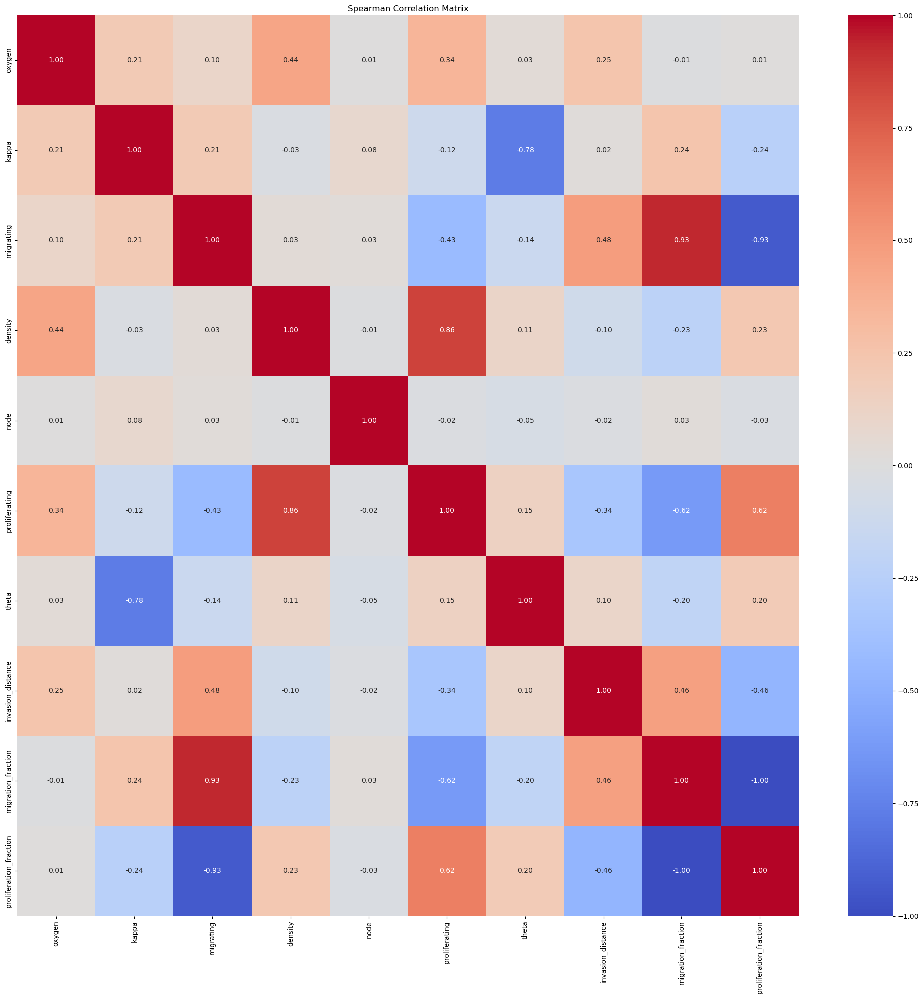

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = "/Users/lexiwhiteside/Downloads/biolgca-master/20052026_lessvessels_noclog/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)
pd.reset_option("display.float_format")
dfs = []
summary_rows = []

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    
    # filter timestep
    df = df[df["time"] > 1960 ]
    
    # keep relevant columns only
    df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

    df["invasion_distance"] = np.abs(df["node"] - 1000)

    # moving front
    #threshold = 1e-6
    #occupied = df[df["density"] > threshold]
    #if len(occupied) > 0:
        #width = occupied["node"].max() - occupied["node"].min() + 1
    #else:
        #width = 0
    
    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)


plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    "oxygen",
    "kappa",
    "migration_fraction",
    "density",
    "proliferation_fraction",
    "invasion_distance",
    "theta"]

data = pooled_active[cols]

# summary stats
summary = pd.DataFrame({
    "mean": data.mean(),
    "median": data.median(),
    "variance": data.var(),
    "std_dev": data.std()})

summary["mode"] = data.mode().iloc[0]
pd.set_option("display.float_format", "{:.3e}".format)
print(summary)


# plot matrix of everything against each other
sns.pairplot(pooled_active[cols], corner=True, plot_kws={"s": 8, "alpha": 0.3})
plt.show()

                            mean    median  variance   std_dev      mode
oxygen                 7.091e-08 5.290e-08 3.595e-15 5.996e-08 1.974e-07
kappa                  1.033e+00 1.319e+00 1.231e+01 3.508e+00 6.154e+00
migration_fraction     1.964e-01 1.000e-01 5.678e-02 2.383e-01 0.000e+00
density                9.360e+00 1.000e+01 1.097e+01 3.312e+00        11
proliferation_fraction 8.036e-01 9.000e-01 5.678e-02 2.383e-01 1.000e+00
invasion_distance      3.515e+02 3.730e+02 3.514e+04 1.875e+02       551
theta                  4.543e-01 4.386e-01 1.105e-01 3.324e-01 0.000e+00


# Large Width

Spearman correlation matrix:
                          oxygen     kappa  migrating   density      node  \
oxygen                  1.000000 -0.216908   0.225469  0.246186 -0.009972   
kappa                  -0.216908  1.000000   0.316354 -0.192844 -0.049869   
migrating               0.225469  0.316354   1.000000  0.267652 -0.017121   
density                 0.246186 -0.192844   0.267652  1.000000  0.003238   
node                   -0.009972 -0.049869  -0.017121  0.003238  1.000000   
proliferating           0.113879 -0.361141  -0.302691  0.809147  0.012096   
theta                   0.470519 -0.733381  -0.227734  0.237091  0.043883   
invasion_distance       0.938656 -0.203602   0.215597  0.237465 -0.072573   
migration_fraction      0.077102  0.389258   0.843753 -0.184265 -0.015044   
proliferation_fraction -0.077102 -0.389258  -0.843753  0.184265  0.015044   

                        proliferating     theta  invasion_distance  \
oxygen                       0.113879  0.470519      

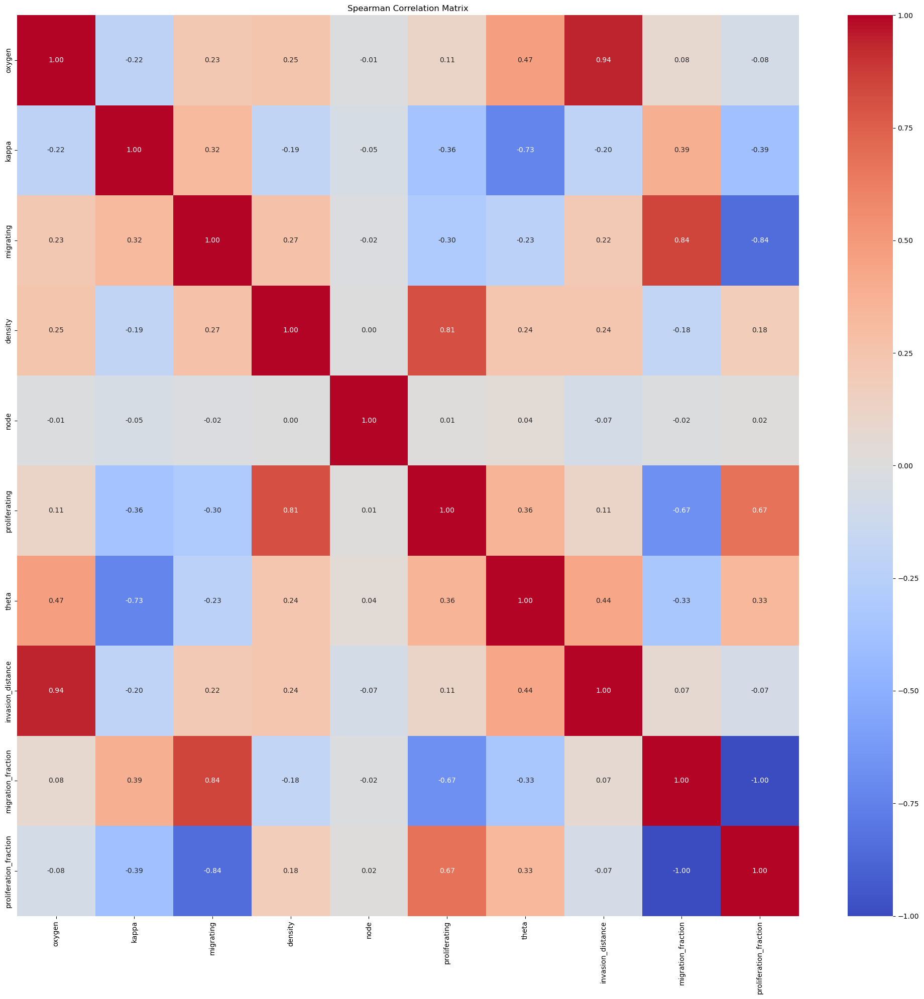

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file = "/Users/lexiwhiteside/Downloads/biolgca-master/14052026_highox/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)
pd.reset_option("display.float_format")
dfs = []
summary_rows = []

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    
    # filter timestep
    df = df[df["time"] > 1960 ]
    
    # keep relevant columns only
    df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating","theta"]].dropna()

    df["invasion_distance"] = np.abs(df["node"] - 1000)

    # moving front
    #threshold = 1e-6
    #occupied = df[df["density"] > threshold]
    #if len(occupied) > 0:
        #width = occupied["node"].max() - occupied["node"].min() + 1
    #else:
        #width = 0
    
    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)


pooled_active = pooled[pooled["density"] > 0].copy()

pooled_active["migration_fraction"] = (pooled_active["migrating"] /pooled_active["density"])
pooled_active["proliferation_fraction"] = (pooled_active["proliferating"] /pooled_active["density"])


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)


plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

                            mean    median  variance   std_dev      mode
oxygen                 2.087e-07 1.932e-07 2.408e-14 1.552e-07 4.935e-07
kappa                  1.106e+00 1.685e+00 9.390e+00 3.064e+00 5.611e+00
migration_fraction     2.782e-01 2.500e-01 5.011e-02 2.238e-01 0.000e+00
density                9.799e+00 1.000e+01 1.116e+01 3.341e+00 1.100e+01
proliferation_fraction 7.218e-01 7.500e-01 5.011e-02 2.238e-01 1.000e+00
invasion_distance      5.145e+02 5.150e+02 2.518e+03 5.018e+01       488
theta                  4.498e-01 3.791e-01 1.198e-01 3.462e-01 0.000e+00


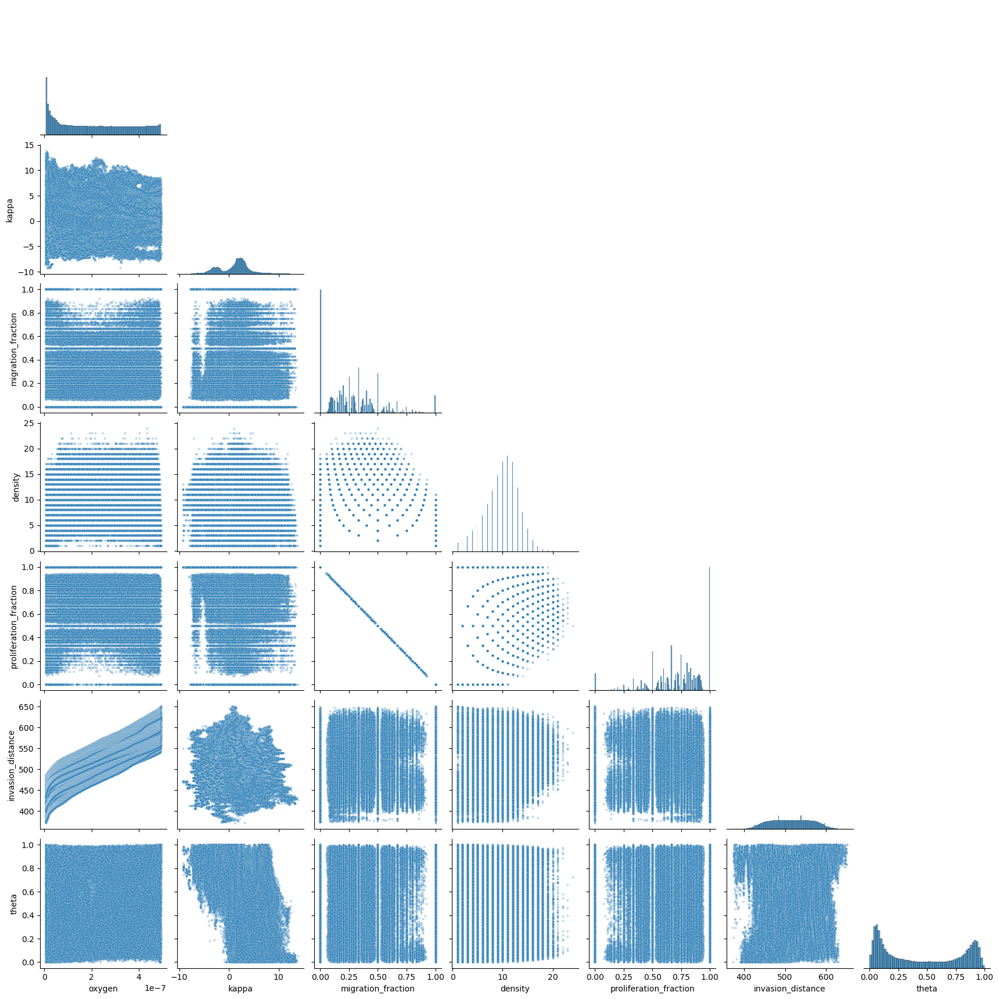

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    "oxygen",
    "kappa",
    "migration_fraction",
    "density",
    "proliferation_fraction",
    "invasion_distance",
    "theta"]

data = pooled_active[cols]

# summary stats
summary = pd.DataFrame({
    "mean": data.mean(),
    "median": data.median(),
    "variance": data.var(),
    "std_dev": data.std()})

summary["mode"] = data.mode().iloc[0]
pd.set_option("display.float_format", "{:.3e}".format)
print(summary)


# plot matrix of everything against each other
sns.pairplot(pooled_active[cols], corner=True, plot_kws={"s": 8, "alpha": 0.3})
plt.show()

# Data

Spearman Correlation Matrix:
                                 patient_id       age  deceased  recurrence  \
patient_id                         1.000000 -0.052365 -0.088442    0.055349   
age                               -0.052365  1.000000  0.226884    0.072474   
deceased                          -0.088442  0.226884  1.000000    0.557561   
recurrence                         0.055349  0.072474  0.557561    1.000000   
p53_status                        -0.555937 -0.741249 -0.748931   -0.423659   
ki_kps_score                      -0.331691 -0.217850 -0.121235   -0.047888   
idh1_status                        0.000000  0.000000  0.000000    0.000000   
mgmt_status                        0.189934  0.721750  0.000000    0.000000   
survival_time_dicom_days          -0.063776 -0.371769 -0.313481   -0.184009   
recurrence_time_dicom_days         0.048417 -0.351399 -0.311019    0.000000   
necrotic_volume                   -0.092384 -0.147937 -0.137171   -0.149690   
active_volume          

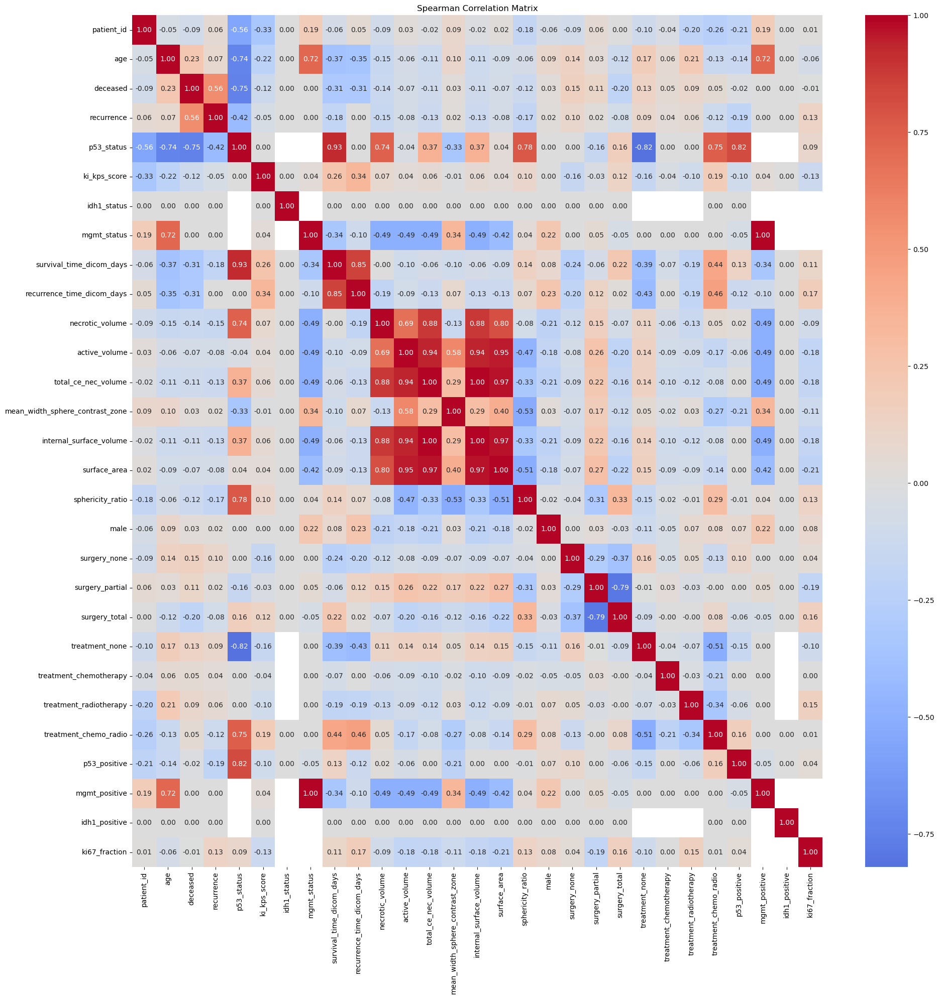

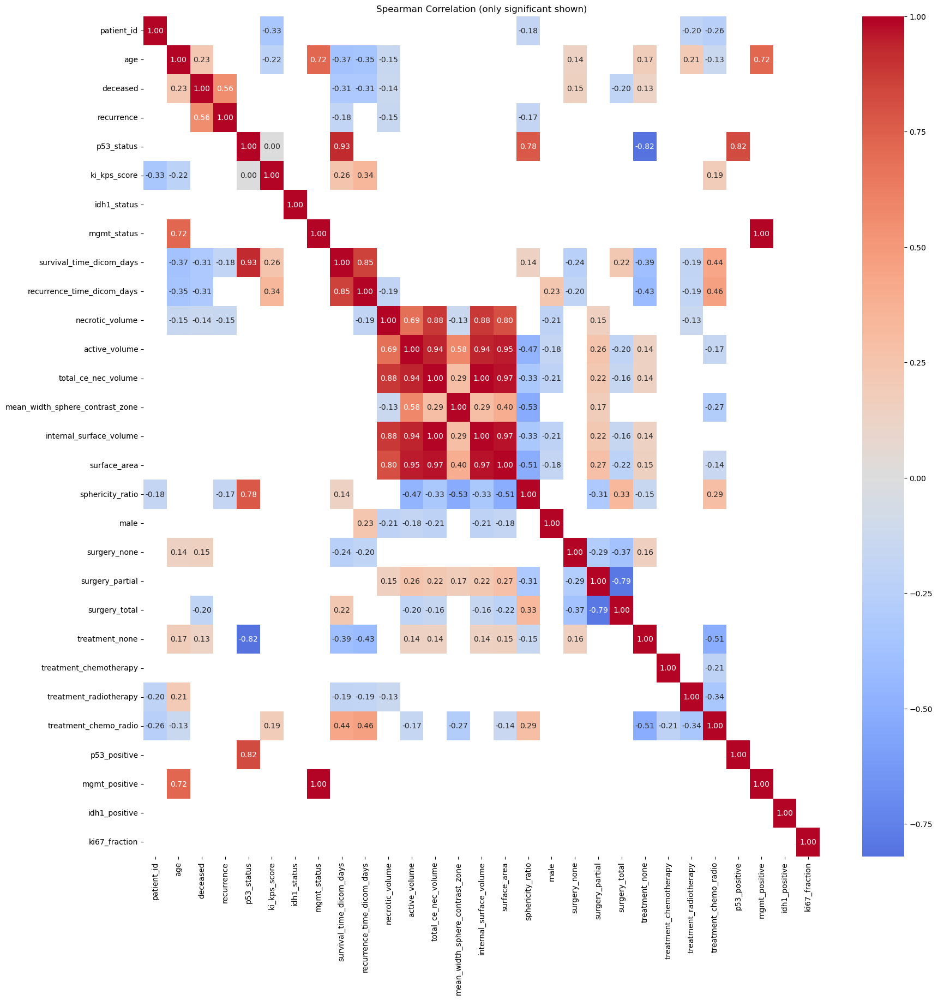

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# Read Excel file
df = pd.read_excel("/Users/lexiwhiteside/Downloads/glioblastoma_cleaned_Lexi.xlsx")


# Columns to keep
cols = df.select_dtypes(include=[np.number]).columns

# ["survival_time_dicom_days","recurrence_time_dicom_days","necrotic_volume","active_volume","total_ce_nec_volume","mean_width_sphere_contrast_zone","internal_surface_volume","surface_area","sphericity_ratio","ki_kps_score","ki67_fraction"]

df_selected = df[cols]
corr, pvals = spearmanr(df_selected, nan_policy='omit')

corr_matrix = pd.DataFrame(corr,index=cols,columns=cols)

p_matrix = pd.DataFrame(pvals,index=cols,columns=cols)

print("Spearman Correlation Matrix:")
print(corr_matrix)

print("\nSpearman P-value Matrix:")
print(p_matrix)

# heatmap
plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

# heatmap again but only show significant correlations
alpha = 0.05
sig_mask = p_matrix > alpha
plt.figure(figsize=(20,20))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    mask=sig_mask
)
plt.title("Spearman Correlation (only significant shown)")
plt.show()


# matrix plot thing
sns.pairplot(df_selected,corner=True,diag_kind="hist")

plt.show()

Spearman Correlation Matrix:
                                 patient_id       age  deceased  recurrence  \
patient_id                         1.000000 -0.052365 -0.088442    0.055349   
age                               -0.052365  1.000000  0.226884    0.072474   
deceased                          -0.088442  0.226884  1.000000    0.557561   
recurrence                         0.055349  0.072474  0.557561    1.000000   
p53_status                        -0.555937 -0.741249 -0.748931   -0.423659   
ki_kps_score                      -0.331691 -0.217850 -0.121235   -0.047888   
idh1_status                        0.000000  0.000000  0.000000    0.000000   
mgmt_status                        0.189934  0.721750  0.000000    0.000000   
survival_time_dicom_days          -0.063776 -0.371769 -0.313481   -0.184009   
recurrence_time_dicom_days         0.048417 -0.351399 -0.311019    0.000000   
necrotic_volume                   -0.092384 -0.147937 -0.137171   -0.149690   
active_volume          

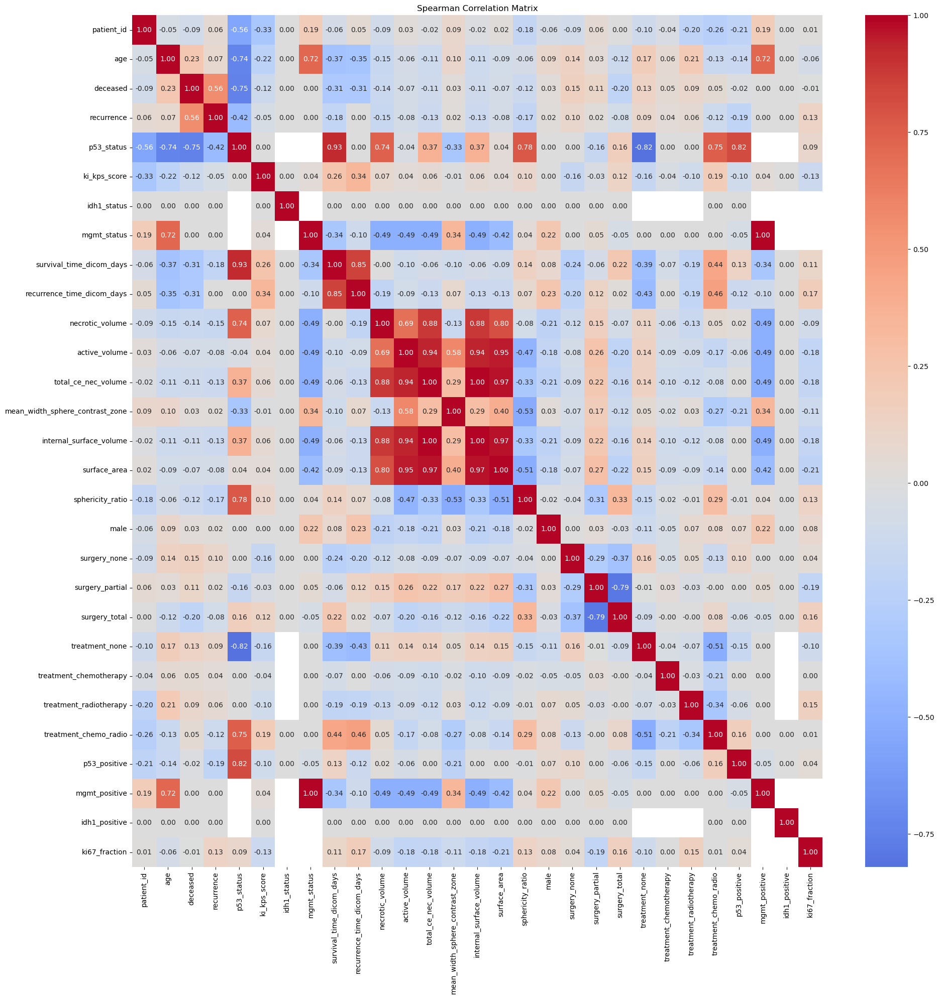

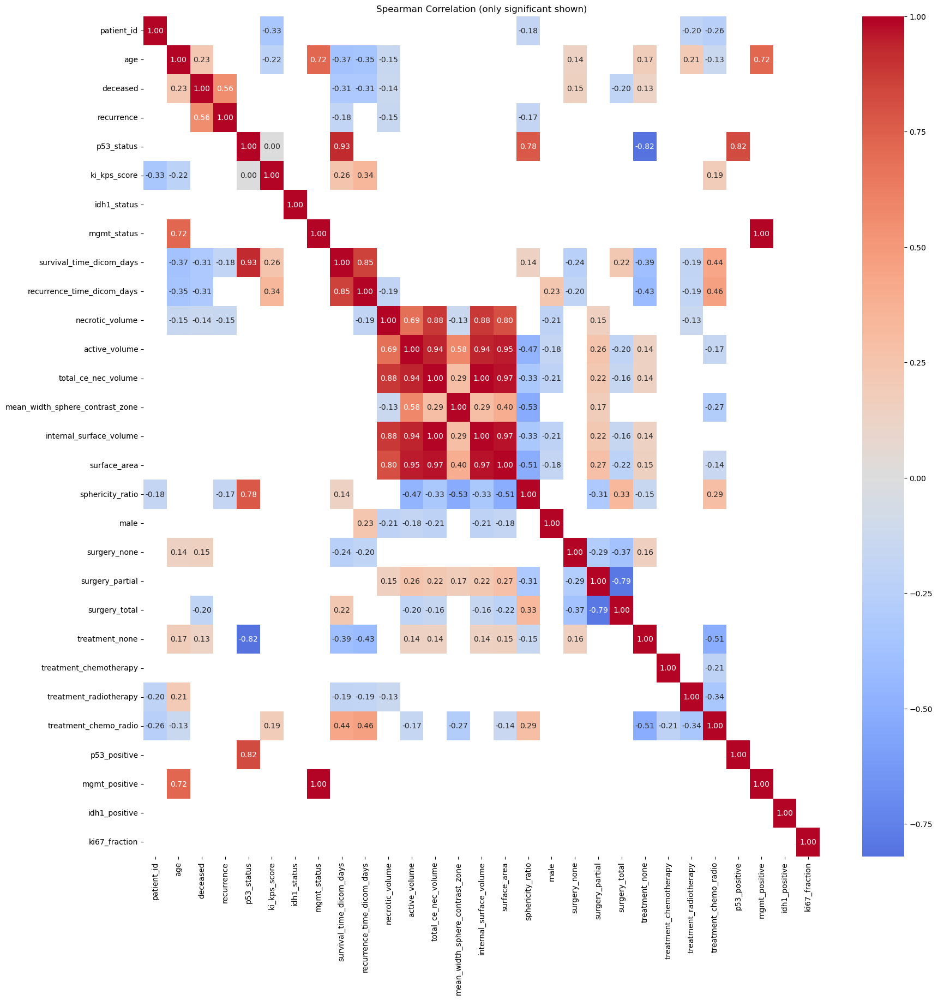

In [14]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# Read Excel file
df = pd.read_excel("/Users/lexiwhiteside/Downloads/glioblastoma_cleaned_Lexi.xlsx")


# Columns to keep
cols = df.select_dtypes(include=[np.number]).columns

# ["survival_time_dicom_days","recurrence_time_dicom_days","necrotic_volume","active_volume","total_ce_nec_volume","mean_width_sphere_contrast_zone","internal_surface_volume","surface_area","sphericity_ratio","ki_kps_score","ki67_fraction"]

df_selected = df[cols]
corr, pvals = spearmanr(df_selected, nan_policy='omit')

corr_matrix = pd.DataFrame(corr,index=cols,columns=cols)

p_matrix = pd.DataFrame(pvals,index=cols,columns=cols)

print("Spearman Correlation Matrix:")
print(corr_matrix)

print("\nSpearman P-value Matrix:")
print(p_matrix)

# heatmap
plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm", center=0, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

# heatmap again but only show significant correlations
alpha = 0.05
sig_mask = p_matrix > alpha
plt.figure(figsize=(20,20))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    mask=sig_mask
)
plt.title("Spearman Correlation (only significant shown)")
plt.show()


# matrix plot thing
sns.pairplot(df_selected,corner=True,diag_kind="hist")

plt.show()

# Extra

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
import os

import os

file = "/Users/lexiwhiteside/Downloads/biolgca-master/06052026_no_clogging_100runs/lgca_1d_no_clogging.xlsx"
xls = pd.ExcelFile(file)

dfs = []
summary_rows = []

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    
    # filter timestep
    df = df[df["time"] > 1960 ]
    
    # keep relevant columns only
    df = df[["oxygen", "kappa", "migrating", "density", "node","proliferating"]].dropna()

    df["invasion_distance"] = df["node"] - 1000

    # moving front
    #threshold = 1e-6
    #occupied = df[df["density"] > threshold]
    #if len(occupied) > 0:
        #width = occupied["node"].max() - occupied["node"].min() + 1
    #else:
        #width = 0
    
    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)
pooled_active = pooled[pooled["density"] > 0].copy()


#corr_matrix = pooled_active.corr(method="spearman")
#print(corr_matrix)

corr, pvals = spearmanr(pooled_active)

corr_matrix = pd.DataFrame(
    corr,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

pval_matrix = pd.DataFrame(
    pvals,
    index=pooled_active.columns,
    columns=pooled_active.columns
)

print("Spearman correlation matrix:")
print(corr_matrix)

print("\nP-value matrix:")
print(pval_matrix)

In [ ]:


# Spearman correlation
rho, pval = spearmanr(pooled["oxygen"], pooled["kappa"])
pooled_active = pooled[pooled["density"] > 0].copy()
print(f"Full kappa rho: {rho}")
print(f"Full kappa p-value: {pval}")
print(f"Full kappa n: {len(pooled)}")


rho2, pval2 = spearmanr(pooled_active["oxygen"], pooled_active["kappa"])
print("Active-only kappa rho:", rho2)
print("Active-only kappa p-value:", pval2)
print("Active-only n:", len(pooled_active))

rho4, pval4 = spearmanr(pooled_active["density"], pooled_active["kappa"])
print("Active-only kappa density rho:", rho4)
print("Active-only kappa density p-value:", pval4)
print("Active-only n:", len(pooled_active))



bins = [-float("inf"), 5.7575e-9, 5.7575e-8, float("inf")]
labels = ["anoxia", "hypoxia", "normoxia"]
pooled_active["oxy_bin"] = pd.cut(pooled_active["oxygen"],bins=bins,labels=labels)
summary1 = pooled_active.groupby("oxy_bin")["kappa"].mean()
print(summary1)


pooled_mig = pooled[pooled["density"] > 0].copy()
pooled_mig["mig_rate"] = pooled_mig["migrating"] / pooled_mig["density"]
rho3, pval3 = spearmanr(pooled_mig["oxygen"], pooled_mig["mig_rate"])
print("Active-only migration rho:", rho3)
print("Active-only migration p-value:", pval3)
print("Active-only n:", len(pooled_mig))

pooled_mig["oxy_bin"] = pd.qcut(pooled_mig["oxygen"], 6)
summary = pooled_mig.groupby("oxy_bin")["mig_rate"].mean()
print(summary)


pooled_mig["high_oxy"] = pooled_mig["oxygen"] > pooled_mig["oxygen"].median()
pooled_mig.groupby("high_oxy")["mig_rate"].mean()
print(pooled_mig.groupby("high_oxy")["mig_rate"].mean())

#scatter plot of oxygen vs kappa
#seaborn package
# invasion distance; distance from final x position to starting position
# width of moving front and correlation w other params

In [ ]:
import seaborn as sns
import seaborn.objects as so
import numpy as np
import matplotlib.pyplot as plt

plt.figure()
sns.scatterplot(data=pooled_active,x="oxygen",y="kappa",s=10,alpha=0.3)
plt.figure()
sns.histplot(data=pooled_active,x="oxygen",y="kappa",bins=100,cbar=True)
plt.figure()
sns.kdeplot(data=pooled_active,x="oxygen", y="kappa", fill=True, levels=30, thresh=0)

sns.regplot(
    data=pooled_active,
    x="oxygen",
    y="kappa",
    lowess=True,
    scatter_kws={"s": 10, "alpha": 0.05}
)

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
import os
import numpy as np

file = "/Users/lexiwhiteside/Downloads/biolgca-master/04242026_1d_yes_clogging/lgca_1d_yes_clogging.xlsx"
xls = pd.ExcelFile(file)

dfs = []

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    
    # filter timestep 999
    df = df[df["time"] == 999]

    # get gradient
    df["gradO"] = np.gradient(df["oxygen"].values)

    
    # keep relevant columns only
    #df = df[["oxygen", "kappa", "migrating", "density"]].dropna()
    
    dfs.append(df)

# combine all runs
pooled = pd.concat(dfs, ignore_index=True)
pooled["kappa"] = pd.to_numeric(pooled["kappa"], errors="coerce")
pooled = pooled.dropna(subset=["kappa"])
print(pooled.dtypes)

mean_kappa = pooled.loc[pooled["density"] > 0, "kappa"].mean()
print("Mean kappa (density > 0, time=999):", mean_kappa)


# Spearman correlation
rho, pval = spearmanr(pooled["oxygen"], pooled["kappa"])
pooled_active = pooled[pooled["density"] > 0].copy()
print(f"Full kappa rho: {rho}")
print(f"Full kappa p-value: {pval}")
print(f"Full kappa n: {len(pooled)}")


rho2, pval2 = spearmanr(pooled_active["oxygen"], pooled_active["kappa"])
print("Active-only kappa rho:", rho2)
print("Active-only kappa p-value:", pval2)
print("Active-only n:", len(pooled_active))

bins = [-float("inf"), 5.7575e-9, 5.7575e-8, float("inf")]
labels = ["anoxia", "hypoxia", "normoxia"]
pooled_active["oxy_bin"] = pd.cut(pooled_active["oxygen"],bins=bins,labels=labels)
summary1 = pooled_active.groupby("oxy_bin")["kappa"].mean()
print(summary1)



pooled_mig = pooled[pooled["density"] > 0].copy()
pooled_mig["mig_rate"] = pooled_mig["migrating"] / pooled_mig["density"]
rho3, pval3 = spearmanr(pooled_mig["oxygen"], pooled_mig["mig_rate"])
print("Active-only migration rho:", rho3)
print("Active-only migration p-value:", pval3)
print("Active-only n:", len(pooled_mig))

pooled_mig["oxy_bin"] = pd.qcut(pooled_mig["oxygen"], 6)
summary = pooled_mig.groupby("oxy_bin")["mig_rate"].mean()
print(summary)
pooled_mig["high_oxy"] = pooled_mig["oxygen"] > pooled_mig["oxygen"].median()
pooled_mig.groupby("high_oxy")["mig_rate"].mean()
print(pooled_mig.groupby("high_oxy")["mig_rate"].mean())

print("kappa vs oxygen:", spearmanr(pooled["kappa"], pooled["oxygen"]))
print("kappa vs |gradO|:", spearmanr(pooled["kappa"], np.abs(pooled["gradO"])))